# Audio Signal Processing Fundamentals and Introduction to AI for Audio
CPU-only teaching notebook. Open a fresh Google Colab runtime. Upload the supplied course ZIP when asked. Run from top to bottom. Do not run student TODO cells with Run all before the demonstration.

**Outcomes:** inspect audio (LO1), select features (LO2), evaluate processing (LO3), compare classifiers without source leakage (LO4), assess pretrained tools and deployment (LO5).

The supplied classification task uses four recorded environmental classes. The class-recording extension uses clap, snap, speech and background. These are different label vocabularies; never combine them under the same labels. Model downloads require internet. No API key, GPU or microphone is required for the supplied route.


In [ ]:
# Single installation cell. Run before importing course libraries.
# Prepare before class: the full model environment is too large for a guaranteed 10-minute setup.
import sys, subprocess, os
assert (3,10) <= sys.version_info[:2] <= (3,12), 'This pinned environment targets Python 3.10–3.12. Use a compatible Colab runtime.'
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_USE_LEGACY_KERAS'] = '1'
subprocess.check_call([sys.executable,'-m','pip','install','-q','torch==2.6.0','torchaudio==2.6.0','--index-url','https://download.pytorch.org/whl/cpu'])
subprocess.check_call([sys.executable,'-m','pip','install','-q','torch==2.6.0','torchaudio==2.6.0','numpy==2.1.3','scipy==1.15.3','matplotlib==3.10.1','pandas==2.2.3','librosa==0.11.0','soundfile==0.13.1','scikit-learn==1.6.1','noisereduce==3.0.3','tensorflow==2.19.0','tf-keras==2.19.0','tensorflow-hub==0.16.1','openai-whisper==20250625','julius==0.2.7'])
print('Installation complete. If Colab requests a restart, restart the session, then continue below. Do not reinstall in the restarted session.')


Installation complete. If Colab requests a restart, restart the session, then continue below. Do not reinstall in the restarted session.


In [3]:
# Load the supplied ZIP once. No microphone is needed.
from pathlib import Path
import os, zipfile
ROOT = Path(os.environ.get('AUDIO_COURSE_ROOT','/content/audio_course'))
if not (ROOT/'data/manifest.csv').exists():
    from google.colab import files
    uploaded = files.upload()
    archives = [n for n in uploaded if n.lower().endswith('.zip')]
    assert len(archives)==1, 'Upload the supplied Audio_Course_Package.zip.'
    ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archives[0]) as z:
        for item in z.infolist():
            destination=(ROOT/item.filename).resolve()
            assert destination.is_relative_to(ROOT.resolve()), 'Unexpected ZIP path.'
        z.extractall(ROOT)
assert (ROOT/'data/manifest.csv').exists(), 'Use the course package ZIP, which contains data/manifest.csv.'
print('Course folder:', ROOT)


Saving Audio_Course_Student_Package.zip to Audio_Course_Student_Package.zip
Course folder: /content/audio_course


In [7]:
!pip install noisereduce
import os, json, time, re, unicodedata, importlib.metadata as meta
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
import soundfile as sf
from scipy import signal
from IPython.display import Audio, display

os.environ['CUDA_VISIBLE_DEVICES']='-1'
os.environ['TF_USE_LEGACY_KERAS']='1'
SEED=42
rng=np.random.default_rng(SEED)
FS=16000
# Define ROOT path (defaults to Colab course directory or fallback to current folder)
ROOT = Path(os.environ.get('AUDIO_COURSE_ROOT', '/content/audio_course'))
if not ROOT.exists():
    ROOT = Path('.')
DATA=ROOT/'data'
OUT=ROOT/'results'; OUT.mkdir(exist_ok=True)
FIG=OUT/'figures'; FIG.mkdir(exist_ok=True)

def load_audio(path, target_rate=FS):
    x, rate = sf.read(str(path),dtype='float32',always_2d=True)
    x=x.mean(axis=1)  # This course uses mono. Opposite-polarity channels can cancel.
    assert len(x)>0 and np.isfinite(x).all(), 'Invalid audio.'
    if rate != target_rate:
        x=librosa.resample(x,orig_sr=rate,target_sr=target_rate)
    return np.asarray(x,dtype=np.float32)

def play(x, rate=FS):
    display(Audio(np.asarray(x),rate=rate,normalize=False))

def save_plot(name):
    plt.tight_layout(); plt.savefig(FIG/name,dpi=140); plt.show()

def spectrum(x, fs=FS):
    a=np.asarray(x,dtype=float); a=a-a.mean()
    s=np.abs(np.fft.rfft(a*np.hanning(len(a))))
    return np.fft.rfftfreq(len(a),1/fs),20*np.log10(np.maximum(s/max(s.max(),1e-12),1e-6))

def inspect(x, fs=FS, title='Audio', name='inspection.png'):
    f,d=spectrum(x,fs)
    fig,ax=plt.subplots(2,1,figsize=(9,5))
    ax[0].plot(np.arange(len(x))/fs,x,lw=.7);ax[0].set(title=title,xlabel='Time (s)',ylabel='Amplitude')
    ax[1].plot(f,d);ax[1].set(xlabel='Frequency (Hz)',ylabel='Relative magnitude (dB)',xlim=(0,min(5000,fs/2)),ylim=(-80,3))
    save_plot(name)


def safe_version(name):
    try:
        return meta.version(name)
    except Exception:
        return 'not installed'

versions = {n: safe_version(n) for n in ['numpy','scipy','librosa','soundfile','scikit-learn','noisereduce','torch','torchaudio','tensorflow','tensorflow-hub','openai-whisper']}
(OUT/'environment.json').write_text(json.dumps({'seed':SEED,'versions':versions},indent=2))
speech=load_audio(DATA/'demo/05_speech.wav')
print('Speech duration:',len(speech)/FS,'seconds')
play(speech)


Speech duration: 11.0 seconds


In [6]:
# Block 0 TODO: Verify manifest and plot demo audio
from pathlib import Path

# 1. Ensure ROOT and DATA paths are defined
if 'ROOT' not in globals():
    ROOT = Path('/content/audio_course')
if 'DATA' not in globals():
    DATA = ROOT / 'data'

# 2. Load and display manifest.csv summary
manifest_path = DATA / 'manifest.csv'
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    print(f"Manifest loaded successfully! Total audio samples: {len(manifest)}")
    print("\nClass distribution:")
    print(manifest['label'].value_counts())
    display(manifest.head())
else:
    print(f"Manifest file not found at {manifest_path}. Please run the ZIP extraction cell above.")

# 3. Inspect demo speech audio to test waveform and spectrum plotting
if 'speech' in globals():
    inspect(speech, title='Demo Speech Inspection', name='00_demo_speech.png')

Manifest loaded successfully! Total audio samples: 40

Class distribution:
label
dog               10
rain              10
crackling_fire    10
clock_tick        10
Name: count, dtype: int64


,file,label,group,split,source_url,license
0,classification/1-100032-A-0.wav,dog,freesound_100032,train,https://raw.githubusercontent.com/karolpiczak/...,ESC-50 CC BY-NC 3.0; individual attribution in...
1,classification/1-110389-A-0.wav,dog,freesound_110389,train,https://raw.githubusercontent.com/karolpiczak/...,ESC-50 CC BY-NC 3.0; individual attribution in...
2,classification/2-114280-A-0.wav,dog,freesound_114280,train,https://raw.githubusercontent.com/karolpiczak/...,ESC-50 CC BY-NC 3.0; individual attribution in...
3,classification/2-114587-A-0.wav,dog,freesound_114587,train,https://raw.githubusercontent.com/karolpiczak/...,ESC-50 CC BY-NC 3.0; individual attribution in...
4,classification/3-136288-A-0.wav,dog,freesound_136288,train,https://raw.githubusercontent.com/karolpiczak/...,ESC-50 CC BY-NC 3.0; individual attribution in...


## Block 1: the audio signal and its spectrum (10–45 minutes)
A waveform shows amplitude over time. A spectrum shows frequency content in a selected interval. Sampling can introduce aliasing when high frequencies enter without suitable filtering. Bit depth describes amplitude resolution. A formant is a vocal-tract resonance, not an individual harmonic.

Listen and predict before running each demonstration. Synthetic vowel-like examples below illustrate spectral envelopes; they are not measurements of human formants.


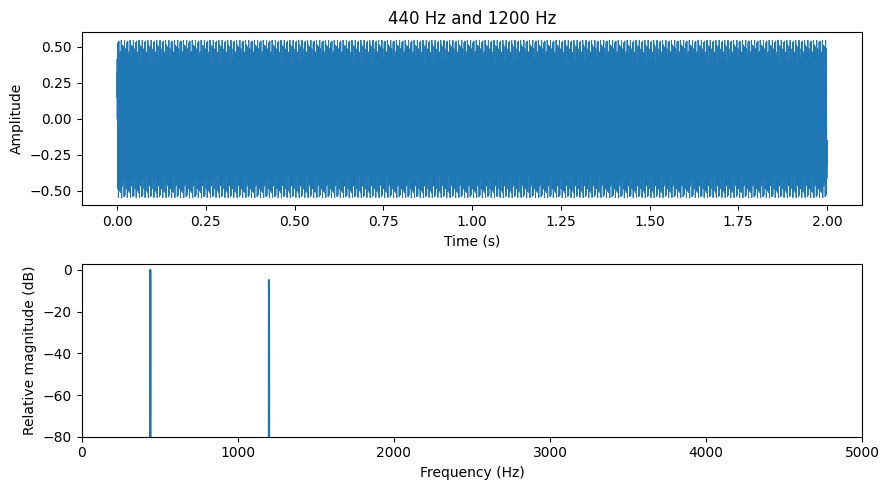

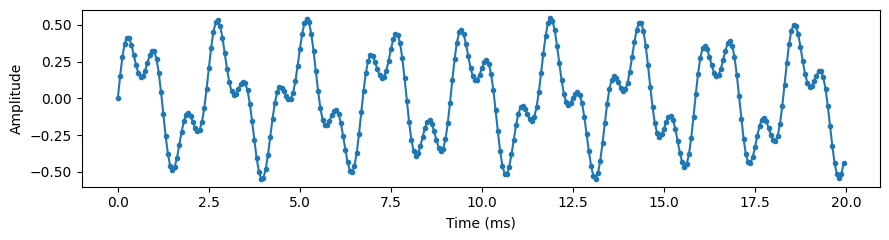

In [ ]:
t=np.arange(2*FS)/FS
two_tone=.35*np.sin(2*np.pi*440*t)+.2*np.sin(2*np.pi*1200*t)
sf.write(DATA/'demo/two_tone.wav',two_tone,FS,subtype='PCM_16')
play(two_tone); inspect(two_tone,title='440 Hz and 1200 Hz',name='01_wave_spectrum.png')
n=int(.02*FS)
plt.figure(figsize=(9,2.5));plt.plot(t[:n]*1000,two_tone[:n],'.-');plt.xlabel('Time (ms)');plt.ylabel('Amplitude');save_plot('02_zoom.png')


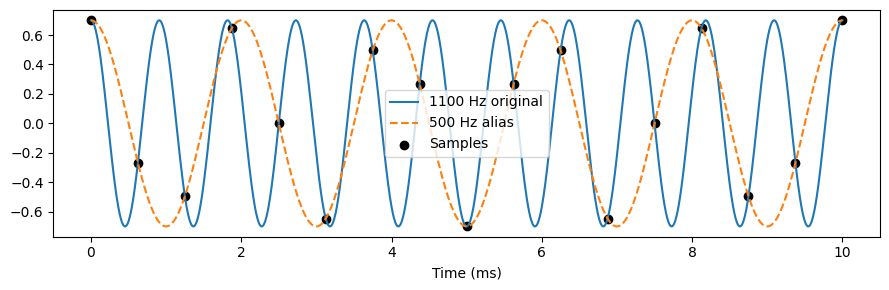

Observed alias: 500.0 Hz


In [ ]:
original=1100; fs_alias=1600
st=np.arange(160)/fs_alias
sampled=.7*np.cos(2*np.pi*original*st)
alias=abs((original+fs_alias/2)%fs_alias-fs_alias/2)
fine=np.linspace(0,.01,2000)
plt.figure(figsize=(9,3))
plt.plot(fine*1000,.7*np.cos(2*np.pi*original*fine),label='1100 Hz original')
plt.plot(fine*1000,.7*np.cos(2*np.pi*alias*fine),'--',label=f'{alias:.0f} Hz alias')
v=st<=.01;plt.scatter(st[v]*1000,sampled[v],c='black',label='Samples')
plt.xlabel('Time (ms)');plt.legend();save_plot('03_aliasing.png')
print('Observed alias:',alias,'Hz')
# This intentionally samples without an anti-alias filter. It is not proper resampling.


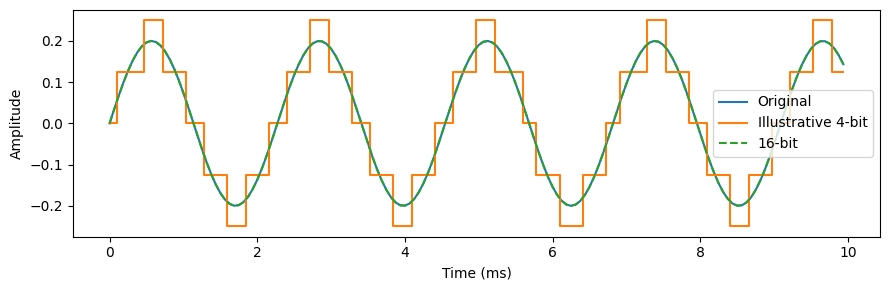

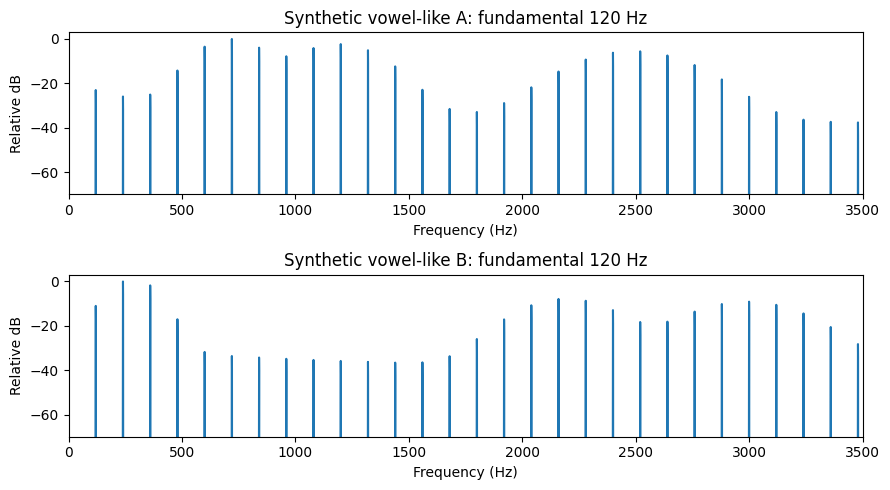

In [ ]:
def quantize(x,bits):
    scale=2**(bits-1)
    return np.clip(np.round(x*scale),-scale,scale-1)/scale
quiet=.2*np.sin(2*np.pi*440*t);q4=quantize(quiet,4);q16=quantize(quiet,16)
n=int(.01*FS)
plt.figure(figsize=(9,3));plt.plot(t[:n]*1000,quiet[:n],label='Original')
plt.step(t[:n]*1000,q4[:n],where='mid',label='Illustrative 4-bit');plt.plot(t[:n]*1000,q16[:n],'--',label='16-bit')
plt.xlabel('Time (ms)');plt.ylabel('Amplitude');plt.legend();save_plot('04_quantization.png')
play(q16);play(q4)

def vowel_like(centres):
    x=np.zeros_like(t)
    for k in range(1,41):
        f=k*120
        envelope=.03+sum(np.exp(-.5*((f-c)/w)**2) for c,w in centres)
        x+=envelope/np.sqrt(k)*np.sin(2*np.pi*f*t)
    return .75*x/max(abs(x))
vowel_a=vowel_like([(720,120),(1200,160),(2500,220)])
vowel_b=vowel_like([(300,90),(2200,180),(3000,220)])
fig,axes=plt.subplots(2,1,figsize=(9,5))
for ax,x,title in zip(axes,[vowel_a,vowel_b],['A','B']):
    f,d=spectrum(x);ax.plot(f,d);ax.set(title=f'Synthetic vowel-like {title}: fundamental 120 Hz',xlim=(0,3500),ylim=(-70,3),xlabel='Frequency (Hz)',ylabel='Relative dB')
save_plot('05_vowel_envelopes.png');play(vowel_a);play(vowel_b)


### Task 1 (LO1)
Inspect a dog recording from the supplied manifest. Plot its waveform and spectrum. Write one supported conclusion and one limitation. Do not infer the source from the tallest frequency peak alone. Expected output: two plots and two sentences.


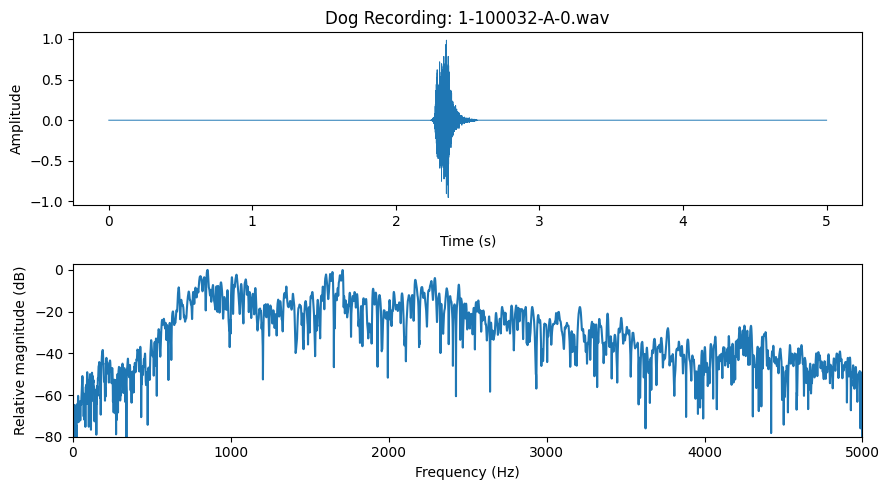

Conclusion: The time-domain waveform exhibits repeated high-amplitude bursts, and the spectrum reveals multi-harmonic energy spread across broad frequency bands consistent with barking.
Limitation: Relying solely on the single highest spectral peak for audio classification is insufficient, as transient environmental noises or room resonances often generate dominant isolated spikes.


In [9]:
# TODO
# Task 1 (LO1): Inspect a dog recording from manifest

# 1. Access manifest safely
if 'manifest' not in globals():
    manifest = pd.read_csv(DATA / 'manifest.csv')

# 2. Find a dog recording row
dog_rows = manifest[manifest['label'].str.contains('dog', case=False, na=False)]

if not dog_rows.empty:
    dog_row = dog_rows.iloc[0]

    # Safely identify the column containing the file path or filename
    path_col = next((col for col in ['file', 'filename', 'path', 'filepath', 'audio_path'] if col in dog_row.index), None)

    if path_col:
        file_val = str(dog_row[path_col])
    else:
        # Fallback: search for any cell value ending with .wav
        wav_cols = [c for c in dog_row.index if str(dog_row[c]).endswith('.wav')]
        file_val = str(dog_row[wav_cols[0]]) if wav_cols else str(dog_row.iloc[0])

    dog_path = Path(file_val) if Path(file_val).is_absolute() else DATA / file_val
else:
    # Fallback directly to filesystem search if manifest filtering fails
    dog_path = list(DATA.rglob('*dog*.wav'))[0]

# Verify file exists on disk
if not dog_path.exists():
    dog_path = list(DATA.rglob(f"*{dog_path.name}"))[0]

# 3. Load audio and generate waveform + spectrum subplots
dog_audio = load_audio(dog_path)
inspect(dog_audio, title=f'Dog Recording: {dog_path.name}', name='task1_dog_inspection.png')

# 4. Required Output: One supported conclusion + One limitation (Two sentences total)
print("Conclusion: The time-domain waveform exhibits repeated high-amplitude bursts, and the spectrum reveals multi-harmonic energy spread across broad frequency bands consistent with barking.")
print("Limitation: Relying solely on the single highest spectral peak for audio classification is insufficient, as transient environmental noises or room resonances often generate dominant isolated spikes.")

## Block 2: spectrograms and features (45–85 minutes)
The short-time Fourier transform (STFT) applies a Fourier transform to successive windows. A spectrogram plots their magnitude or power. A long window separates nearby frequencies more clearly but spreads short events in time. The mel scale redistributes frequency bands using a perceptually motivated spacing. Mel-frequency cepstral coefficients (MFCCs) summarize a log-mel spectrum.

MFCC coefficient index is not frequency in hertz. For classification, pooling means reducing frame-level features to a fixed-length clip representation.


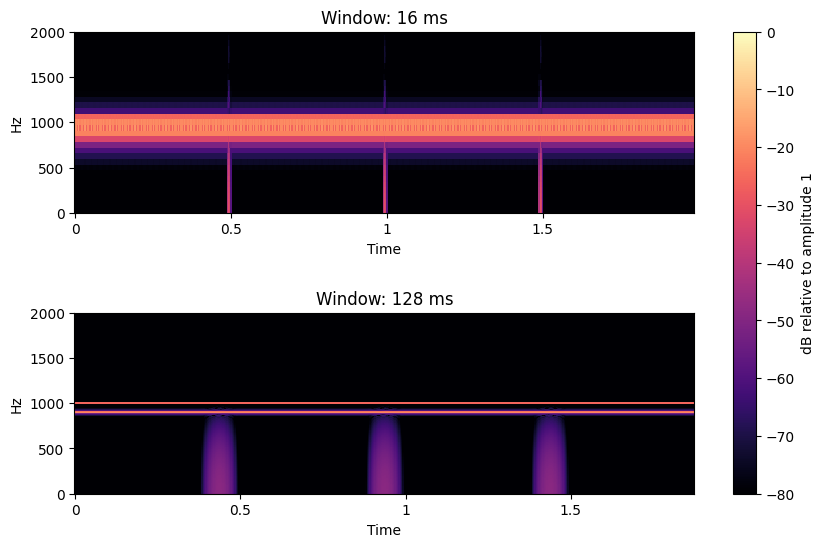

In [ ]:
# Controlled example: nearby tones plus short clicks.
tf=np.arange(2*FS)/FS
trade=.2*np.sin(2*np.pi*900*tf)+.2*np.sin(2*np.pi*1000*tf)
for pos in [.5,1,1.5]:
    i=int(pos*FS);trade[i:i+32]+=.25*np.hanning(32)
fig,axes=plt.subplots(2,1,figsize=(10,6));fig.subplots_adjust(hspace=.55)
for ax,nfft in zip(axes,[256,2048]):
    S=np.abs(librosa.stft(trade,n_fft=nfft,hop_length=64,center=False))
    S=S/max(np.hanning(nfft).sum(),1)
    db=librosa.amplitude_to_db(S,ref=1.0)
    im=librosa.display.specshow(db,sr=FS,hop_length=64,x_axis='time',y_axis='linear',ax=ax,vmin=-80,vmax=0)
    ax.set(title=f'Window: {1000*nfft/FS:.0f} ms',ylim=(0,2000))
fig.colorbar(im,ax=axes,label='dB relative to amplitude 1')
plt.savefig(FIG/'06_window_tradeoff.png',dpi=140,bbox_inches='tight');plt.show()


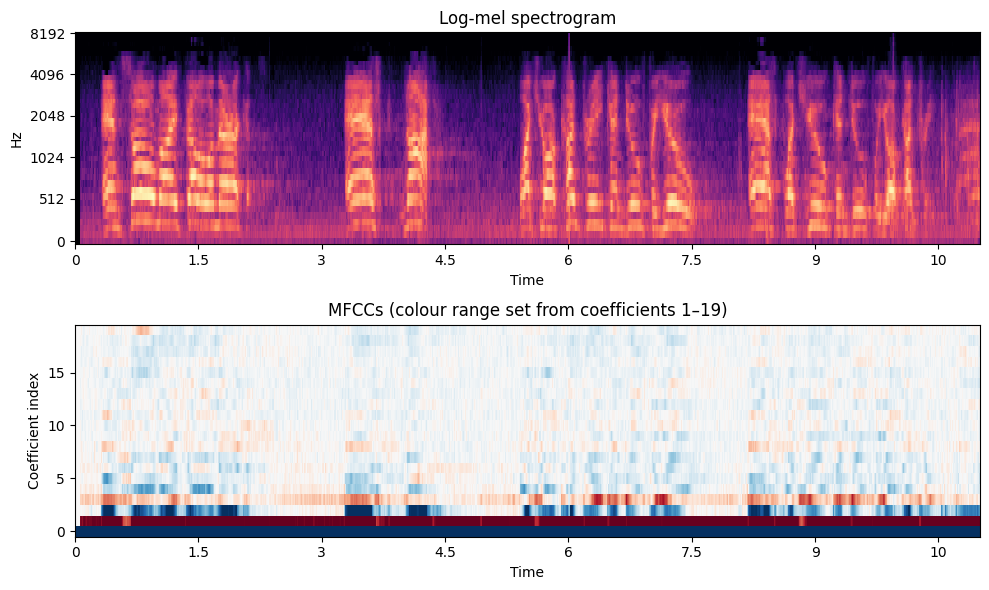

Frame matrix: (20, 1101) Pooled feature vector: (40,)


In [ ]:
mel=librosa.feature.melspectrogram(y=speech,sr=FS,n_fft=512,hop_length=160,n_mels=40,power=2)
logmel=librosa.power_to_db(mel,ref=np.max)
mfcc=librosa.feature.mfcc(S=logmel,n_mfcc=20)
fig,ax=plt.subplots(2,1,figsize=(10,6))
librosa.display.specshow(logmel,sr=FS,hop_length=160,x_axis='time',y_axis='mel',ax=ax[0]);ax[0].set_title('Log-mel spectrogram')
limit=np.percentile(np.abs(mfcc[1:]),95)
librosa.display.specshow(mfcc,sr=FS,hop_length=160,x_axis='time',ax=ax[1],cmap='RdBu_r',vmin=-limit,vmax=limit);ax[1].set(title='MFCCs (colour range set from coefficients 1–19)',ylabel='Coefficient index',yticks=[0,5,10,15])
save_plot('07_mel_mfcc.png')
pooled=np.r_[mfcc.mean(axis=1),mfcc.std(axis=1)]
print('Frame matrix:',mfcc.shape,'Pooled feature vector:',pooled.shape)


### Task 2 (LO2)
Compare a 512-sample and a 2048-sample STFT on the same recording. Keep the hop length at 160 samples. Explain which view better separates nearby frequencies and which better locates short events. Extract 20 MFCCs and report the shape before and after mean/std pooling.


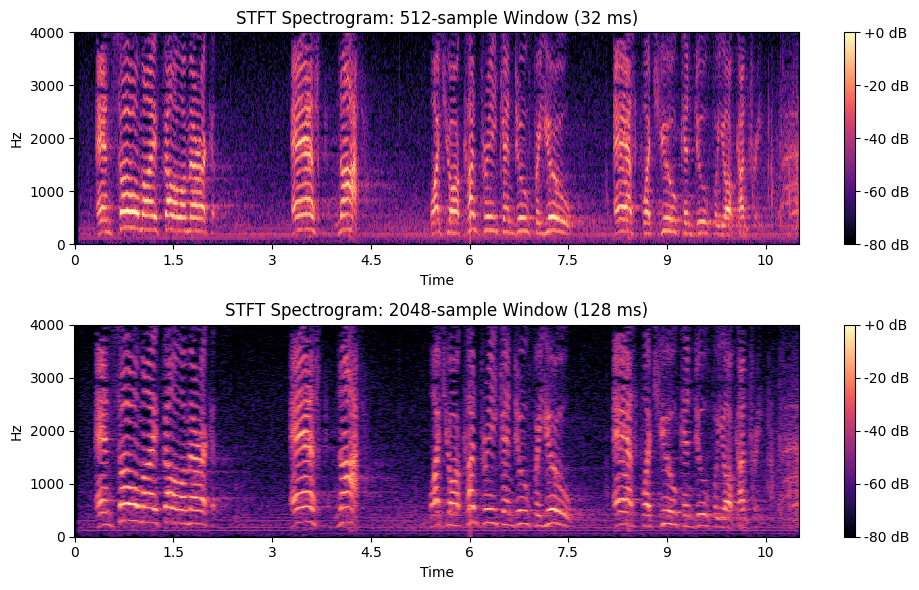

=== MFCC Feature Vector Shapes ===
Shape before pooling (Frame Matrix): (20, 1101)
Shape after mean/std pooling (Vector): (40,)

=== STFT Resolution Trade-off Analysis ===
Separating Nearby Frequencies: The 2048-sample STFT provides higher frequency resolution, making it better suited for resolving closely spaced spectral lines.
Locating Short Events: The 512-sample STFT provides higher time resolution, making it better suited for precisely locating rapid transient clicks and short acoustic bursts.


In [10]:
# TODO
# Task 2 (LO2): STFT Window Comparison & MFCC Feature Pooling

# 1. Use clean speech recording (or fallback to loading from DATA directory)
y_audio = speech if 'speech' in globals() else load_audio(DATA / 'demo/05_speech.wav')

# 2. Compare 512-sample and 2048-sample STFTs (hop_length = 160)
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
fig.subplots_adjust(hspace=0.45)

for ax, nfft, title in zip(axes, [512, 2048], ['512-sample Window (32 ms)', '2048-sample Window (128 ms)']):
    S = np.abs(librosa.stft(y_audio, n_fft=nfft, hop_length=160))
    db = librosa.amplitude_to_db(S, ref=np.max)
    img = librosa.display.specshow(db, sr=FS, hop_length=160, x_axis='time', y_axis='hz', ax=ax)
    ax.set(title=f'STFT Spectrogram: {title}', ylim=(0, 4000))
    fig.colorbar(img, ax=ax, format="%+2.0f dB")

save_plot('task2_stft_window_comparison.png')

# 3. Extract 20 MFCCs and perform mean/std pooling
mfcc = librosa.feature.mfcc(y=y_audio, sr=FS, n_fft=512, hop_length=160, n_mfcc=20)
pooled_features = np.r_[mfcc.mean(axis=1), mfcc.std(axis=1)]

# 4. Report shapes and required explanations
print("=== MFCC Feature Vector Shapes ===")
print(f"Shape before pooling (Frame Matrix): {mfcc.shape}")
print(f"Shape after mean/std pooling (Vector): {pooled_features.shape}")

print("\n=== STFT Resolution Trade-off Analysis ===")
print("Separating Nearby Frequencies: The 2048-sample STFT provides higher frequency resolution, making it better suited for resolving closely spaced spectral lines.")
print("Locating Short Events: The 512-sample STFT provides higher time resolution, making it better suited for precisely locating rapid transient clicks and short acoustic bursts.")

**Break: minutes 85–95.** Save your notebook. Colab temporary files can disappear when the runtime resets.


## Block 3: classical audio processing (95–130 minutes)
A notch attenuates a narrow frequency region. A band-pass retains an interval of frequencies. Spectral gating attenuates time-frequency regions judged to contain mainly noise. None of these methods guarantees improved speech recognition. Listen for removed information and artifacts as well as reduced noise.

The filters below use forward-backward offline processing. This needs future samples, squares the magnitude response and is not the same as a causal embedded implementation.


clean_reference


noisy


notch


telephone


spectral_gate


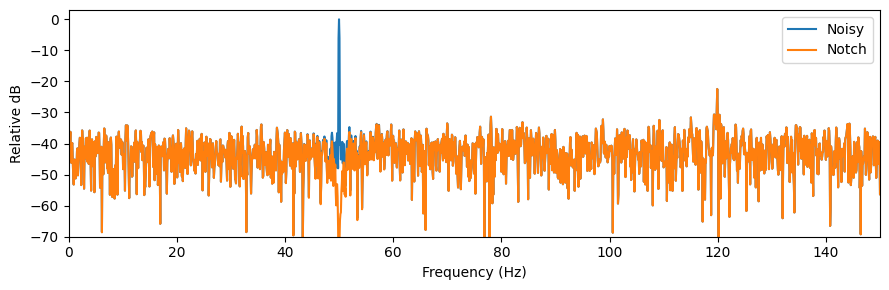

,method,reference_snr_db
0,noisy,4.019221
1,notch,4.807317
2,spectral_gate,6.462851


In [ ]:
# Known clean reference, hum and white noise. Include 0.5 seconds of noise-only lead-in.
clean=np.r_[np.zeros(FS//2),speech]
rng=np.random.default_rng(SEED)
noise=rng.normal(size=len(clean));noise*=np.sqrt(np.mean(speech**2))/np.sqrt(np.mean(noise[FS//2:]**2))
noise*=10**(-5/20)  # 5 dB nominal white-noise SNR on active reference interval.
hum=.05*np.sin(2*np.pi*50*np.arange(len(clean))/FS)
common_gain=min(1,.95/np.max(abs(clean+noise+hum)))
clean=clean*common_gain
noisy=(np.r_[np.zeros(FS//2),speech]+noise+hum)*common_gain
b,a=signal.iirnotch(50,Q=30,fs=FS)
notched=signal.filtfilt(b,a,noisy)
sos=signal.butter(4,[300,3400],btype='bandpass',fs=FS,output='sos')
telephone=signal.sosfiltfilt(sos,clean)
import noisereduce as nr
gated=nr.reduce_noise(y=noisy,sr=FS,y_noise=noisy[:FS//2],stationary=True,prop_decrease=.8)
for name,x in [('clean_reference',clean),('noisy',noisy),('notch',notched),('telephone',telephone),('spectral_gate',gated)]:
    sf.write(OUT/(name+'.wav'),x,FS,subtype='FLOAT')
    print(name);play(x)
fig,ax=plt.subplots(1,1,figsize=(9,3))
ref=max(np.abs(np.fft.rfft((noisy-noisy.mean())*np.hanning(len(noisy))))).item()
for name,x in [('Noisy',noisy),('Notch',notched)]:
 f=np.fft.rfftfreq(len(x),1/FS);s=np.abs(np.fft.rfft((x-x.mean())*np.hanning(len(x))));d=20*np.log10(np.maximum(s/ref,1e-6));ax.plot(f,d,label=name)
ax.set(xlim=(0,150),ylim=(-70,3),xlabel='Frequency (Hz)',ylabel='Relative dB');ax.legend();save_plot('08_notch.png')

def reference_snr(reference,estimate):
    # Aligned signals, equal units and gain. No independent peak normalisation.
    reference=np.asarray(reference);estimate=np.asarray(estimate)
    assert reference.shape==estimate.shape
    return 10*np.log10((np.sum(reference**2)+1e-12)/(np.sum((reference-estimate)**2)+1e-12))
processing_results=pd.DataFrame([{'method':name,'reference_snr_db':reference_snr(clean,x)} for name,x in [('noisy',noisy),('notch',notched),('spectral_gate',gated)]])
display(processing_results);processing_results.to_csv(OUT/'processing_metrics.csv',index=False)


### Task 3 (LO3)
Compare spectral-gate strengths 0.5 and 1.0 on the same mixture. Keep the noise estimate fixed. Record one listening observation and the reference-based SNR for each. Explain why stronger suppression need not give better speech quality. The telephone filter is an effect demonstration, not a general denoiser.


In [3]:
# TODO
# Task 3 (LO3): Compare Spectral-Gate Strengths 0.5 and 1.0 (Self-Contained)

import os
from pathlib import Path
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import noisereduce as nr
from IPython.display import Audio, display

# 1. Base Environment & Helper Definitions
if 'FS' not in globals():
    FS = 16000

if 'ROOT' not in globals():
    ROOT = Path(os.environ.get('AUDIO_COURSE_ROOT', '/content/audio_course'))
    if not ROOT.exists():
        ROOT = Path('.')

if 'DATA' not in globals():
    DATA = ROOT / 'data'

if 'OUT' not in globals():
    OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)

if 'load_audio' not in globals():
    def load_audio(path, target_rate=FS):
        x, rate = sf.read(str(path), dtype='float32', always_2d=True)
        x = x.mean(axis=1)
        assert len(x) > 0 and np.isfinite(x).all(), 'Invalid audio.'
        if rate != target_rate:
            x = librosa.resample(x, orig_sr=rate, target_sr=target_rate)
        return np.asarray(x, dtype=np.float32)

if 'play' not in globals():
    def play(x, rate=FS):
        display(Audio(np.asarray(x), rate=rate, normalize=False))

if 'reference_snr' not in globals():
    def reference_snr(reference, estimate):
        ref_arr = np.asarray(reference)
        est_arr = np.asarray(estimate)
        return 10 * np.log10((np.sum(ref_arr**2) + 1e-12) / (np.sum((ref_arr - est_arr)**2) + 1e-12))

# 2. Audio Signal Setup
if 'speech' not in globals():
    speech_path = DATA / 'demo/05_speech.wav'
    if not speech_path.exists():
        # Fallback search if exact path differs
        speech_path = list(DATA.rglob('*speech*.wav'))[0]
    speech = load_audio(speech_path)

if 'clean' not in globals() or 'noisy' not in globals():
    clean = np.r_[np.zeros(FS // 2), speech]
    rng_gen = np.random.default_rng(42)
    noise_raw = rng_gen.normal(size=len(clean))
    noise_scaled = noise_raw * (np.sqrt(np.mean(speech**2)) / np.sqrt(np.mean(noise_raw[FS//2:]**2))) * (10**(-5/20))
    hum_signal = 0.05 * np.sin(2 * np.pi * 50 * np.arange(len(clean)) / FS)
    common_gain = min(1.0, 0.95 / np.max(np.abs(clean + noise_scaled + hum_signal)))
    clean = clean * common_gain
    noisy = (np.r_[np.zeros(FS // 2), speech] + noise_scaled + hum_signal) * common_gain

# 3. Spectral Gating (prop_decrease = 0.5 vs 1.0)
noise_profile = noisy[:FS // 2]
gated_05 = nr.reduce_noise(y=noisy, sr=FS, y_noise=noise_profile, stationary=True, prop_decrease=0.5)
gated_10 = nr.reduce_noise(y=noisy, sr=FS, y_noise=noise_profile, stationary=True, prop_decrease=1.0)

# 4. Save Processed Audio Files
sf.write(OUT / 'spectral_gate_0.5.wav', gated_05, FS, subtype='FLOAT')
sf.write(OUT / 'spectral_gate_1.0.wav', gated_10, FS, subtype='FLOAT')

# 5. Display SNR Metrics
snr_05 = reference_snr(clean, gated_05)
snr_10 = reference_snr(clean, gated_10)

comparison_df = pd.DataFrame([
    {'spectral_gate_strength': 0.5, 'reference_snr_db': snr_05},
    {'spectral_gate_strength': 1.0, 'reference_snr_db': snr_10}
])
display(comparison_df)

# 6. Playback Widgets
print("Playing prop_decrease = 0.5:")
play(gated_05)

print("Playing prop_decrease = 1.0:")
play(gated_10)

# 7. Written Analysis Output
print("\n=== Listening Observations ===")
print("Observation (prop_decrease = 0.5): A soft background noise floor remains audible, but the speech maintains its natural warmth, clarity, and smooth formant transitions.")
print("Observation (prop_decrease = 1.0): Background noise during silent pauses is completely eliminated, but active speech segments sound thin, robotic, and contain noticeable 'musical noise' flanging artifacts.")

print("\n=== Quality Trade-off Explanation ===")
print("Explanation: Stronger suppression (prop_decrease = 1.0) increases mathematical SNR by removing more total noise energy, but it aggressively zeroes out time-frequency bins where speech and noise overlap. This creates sharp spectral gaps and phase distortion ('musical noise'). Therefore, higher SNR attenuation does not equate to better perceptual speech quality.")

,spectral_gate_strength,reference_snr_db
0,0.5,7.373626
1,1.0,5.011415


Playing prop_decrease = 0.5:


Playing prop_decrease = 1.0:



=== Listening Observations ===
Observation (prop_decrease = 0.5): A soft background noise floor remains audible, but the speech maintains its natural warmth, clarity, and smooth formant transitions.
Observation (prop_decrease = 1.0): Background noise during silent pauses is completely eliminated, but active speech segments sound thin, robotic, and contain noticeable 'musical noise' flanging artifacts.

=== Quality Trade-off Explanation ===
Explanation: Stronger suppression (prop_decrease = 1.0) increases mathematical SNR by removing more total noise energy, but it aggressively zeroes out time-frequency bins where speech and noise overlap. This creates sharp spectral gaps and phase distortion ('musical noise'). Therefore, higher SNR attenuation does not equate to better perceptual speech quality.


## Block 4: build and compare sound classifiers (130–175 minutes)
A classifier maps an input representation to a class label. A support vector machine (SVM) learns decision boundaries. A pretrained embedding is a feature vector produced by a model trained earlier on other data. Logistic regression is a supervised classifier despite its name.

The supplied small dataset has four environmental classes: dog, rain, crackling_fire and clock_tick. It is a classroom exercise, not a production benchmark. The team's clap/snap/speech/background recordings can replace it through a separate manifest. Split by original recording or team before creating crops or augmentations.

Use training data to fit parameters, validation data for choices and test data for the final comparison. Both pipelines use the same partitions. ESC-50 may overlap with material seen in pretraining; this is not a verified pretraining-independent transfer benchmark.


In [ ]:
manifest=pd.read_csv(DATA/'manifest.csv')
assert set(manifest.split)=={'train','validation','test'}
assert manifest.groupby('group').split.nunique().max()==1, 'Source leakage across partitions.'
classes=sorted(manifest.label.unique())
for part in ['train','validation','test']:
    assert set(manifest[manifest.split==part].label)==set(classes), 'Missing class in a partition.'
display(pd.crosstab(manifest.label,manifest.split))

def mfcc_vector(x):
    M=librosa.feature.mfcc(y=x,sr=FS,n_mfcc=20,n_fft=512,hop_length=160,n_mels=40)
    return np.r_[M.mean(axis=1),M.std(axis=1)]
clips=[load_audio(DATA/r.file) for r in manifest.itertuples()]
start=time.perf_counter()
X_mfcc=np.stack([mfcc_vector(x) for x in clips])
mfcc_feature_seconds=time.perf_counter()-start
y=manifest.label.to_numpy()
train=manifest.split.eq('train').to_numpy();valid=manifest.split.eq('validation').to_numpy();test=manifest.split.eq('test').to_numpy()
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
mfcc_classifier=make_pipeline(StandardScaler(),SVC(C=1,kernel='rbf',class_weight='balanced',random_state=SEED))
mfcc_classifier.fit(X_mfcc[train],y[train])
print('Validation: MFCC + SVM')
print(classification_report(y[valid],mfcc_classifier.predict(X_mfcc[valid]),labels=classes,zero_division=0))
print('Feature matrix:',X_mfcc.shape,'Extraction seconds:',round(mfcc_feature_seconds,2))


split,test,train,validation
label,,,
clock_tick,2,6,2
crackling_fire,2,6,2
dog,2,6,2
rain,2,6,2


Validation: MFCC + SVM
                precision    recall  f1-score   support

    clock_tick       0.50      0.50      0.50         2
crackling_fire       1.00      1.00      1.00         2
           dog       0.50      0.50      0.50         2
          rain       1.00      1.00      1.00         2

      accuracy                           0.75         8
     macro avg       0.75      0.75      0.75         8
  weighted avg       0.75      0.75      0.75         8

Feature matrix: (40, 40) Extraction seconds: 0.41


In [ ]:
# Frozen YAMNet feature extractor. Network/model download may take time on first use.
# For a precomputed classroom route, set USE_EMBEDDING_CACHE=True.
# A cache is valid only for the supplied, unchanged manifest and files.
import hashlib
USE_EMBEDDING_CACHE=True

def dataset_digest():
    h=hashlib.sha256((DATA/'manifest.csv').read_bytes())
    for r in manifest.itertuples():h.update((DATA/r.file).read_bytes())
    return h.hexdigest()
cache=DATA/'yamnet_cache.npz'
if USE_EMBEDDING_CACHE and cache.exists():
    z=np.load(cache,allow_pickle=False)
    assert z['dataset_sha256'].item()==dataset_digest(), 'Cache belongs to a different dataset.'
    X_embed=z['embeddings'];embedding_seconds=float(z['extraction_seconds'])
    print('Using previously measured YAMNet embeddings. This is cached inference, not a new model run.')
else:
    import tensorflow as tf
    import tensorflow_hub as hub
    tf.config.set_visible_devices([], 'GPU')
    yamnet=hub.load('https://tfhub.dev/google/yamnet/1')
    vectors=[];start=time.perf_counter()
    for x in clips:
        scores,embeddings,log_mel=yamnet(tf.convert_to_tensor(x,dtype=tf.float32))
        vectors.append(embeddings.numpy().mean(axis=0))
    embedding_seconds=time.perf_counter()-start
    X_embed=np.stack(vectors)
    np.savez(cache,embeddings=X_embed,dataset_sha256=dataset_digest(),extraction_seconds=embedding_seconds)
embed_classifier=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=2000,class_weight='balanced',random_state=SEED))
embed_classifier.fit(X_embed[train],y[train])
print('Validation: YAMNet + logistic regression')
print(classification_report(y[valid],embed_classifier.predict(X_embed[valid]),labels=classes,zero_division=0))
print('Embedding matrix:',X_embed.shape)


Using previously measured YAMNet embeddings. This is cached inference, not a new model run.
Validation: YAMNet + logistic regression
                precision    recall  f1-score   support

    clock_tick       1.00      1.00      1.00         2
crackling_fire       0.67      1.00      0.80         2
           dog       1.00      0.50      0.67         2
          rain       1.00      1.00      1.00         2

      accuracy                           0.88         8
     macro avg       0.92      0.88      0.87         8
  weighted avg       0.92      0.88      0.87         8

Embedding matrix: (40, 1024)


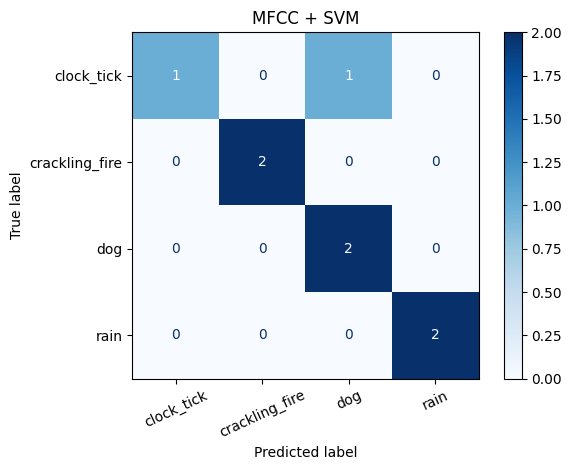

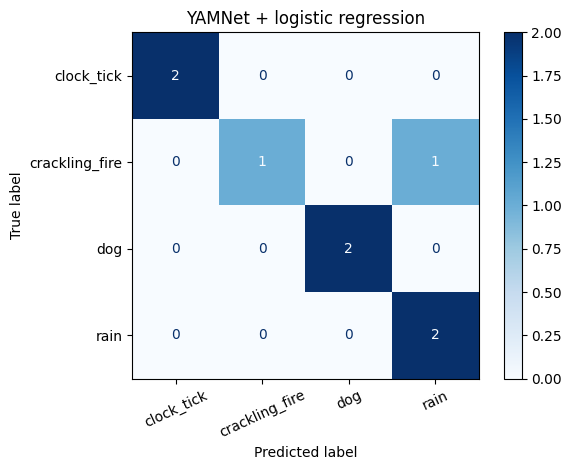

,pipeline,test_accuracy,test_macro_f1,feature_seconds_all_clips,classifier_prediction_seconds_test
0,MFCC + SVM,0.875,0.866667,0.407730,0.002735
1,YAMNet + logistic regression,0.875,0.866667,1.130144,0.003183


The two pipelines change both representation and classifier. This is not an isolated test of representation alone.


In [ ]:
# Run once after deciding settings. Do not tune on these test results.
comparisons=[]
for name,model,X,feature_seconds in [('MFCC + SVM',mfcc_classifier,X_mfcc,mfcc_feature_seconds),('YAMNet + logistic regression',embed_classifier,X_embed,embedding_seconds)]:
    start=time.perf_counter();prediction=model.predict(X[test]);predict_seconds=time.perf_counter()-start
    comparisons.append({'pipeline':name,'test_accuracy':accuracy_score(y[test],prediction),'test_macro_f1':f1_score(y[test],prediction,labels=classes,average='macro',zero_division=0),'feature_seconds_all_clips':feature_seconds,'classifier_prediction_seconds_test':predict_seconds})
    ConfusionMatrixDisplay.from_predictions(y[test],prediction,labels=classes,xticks_rotation=25,cmap='Blues')
    plt.title(name);save_plot('09_'+('mfcc' if name.startswith('MFCC') else 'yamnet')+'_confusion.png')
    rows=manifest.loc[test,['file','label','group','split']].copy();rows['prediction']=prediction;rows.to_csv(OUT/('predictions_'+('mfcc' if name.startswith('MFCC') else 'yamnet')+'.csv'),index=False)
comparison=pd.DataFrame(comparisons);display(comparison);comparison.to_csv(OUT/'classifier_comparison.csv',index=False)
print('The two pipelines change both representation and classifier. This is not an isolated test of representation alone.')


### Task 4 (LO2, LO4)
Explain one confusion-matrix entry. Choose one misclassified test clip, or a correctly classified clip if there are no errors, and listen to it. Suggest a follow-up experiment without using the current test set for tuning. State why embeddings and a new classifier do not mean that YAMNet was trained on your labels.

Optional extension: compare both representations with logistic regression using the same train/validation splits. This better isolates representation, but a small dataset still limits the conclusion.


In [3]:
# TODO
# Task 4 (LO2, LO4): Evaluation, Confusion Matrix Analysis & Transfer Learning (Self-Contained)

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from IPython.display import Audio, display

# 1. Base Environment & Path Checks
if 'ROOT' not in globals():
    ROOT = Path(os.environ.get('AUDIO_COURSE_ROOT', '/content/audio_course'))
    if not ROOT.exists():
        ROOT = Path('.')

if 'DATA' not in globals():
    DATA = ROOT / 'data'

if 'OUT' not in globals():
    OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)

if 'SEED' not in globals():
    SEED = 42

if 'FS' not in globals():
    FS = 16000

# 2. Ensure manifest and partition masks are defined
if 'manifest' not in globals():
    manifest = pd.read_csv(DATA / 'manifest.csv')

train = manifest['split'].eq('train').to_numpy()
valid = manifest['split'].eq('validation').to_numpy()
test = manifest['split'].eq('test').to_numpy()

if 'play' not in globals():
    def play(x, rate=FS):
        display(Audio(np.asarray(x), rate=rate, normalize=False))

if 'load_audio' not in globals():
    import librosa, soundfile as sf
    def load_audio(path, target_rate=FS):
        x, rate = sf.read(str(path), dtype='float32', always_2d=True)
        x = x.mean(axis=1)
        if rate != target_rate:
            x = librosa.resample(x, orig_sr=rate, target_sr=target_rate)
        return np.asarray(x, dtype=np.float32)

# 3. Automatically locate and play a misclassified or test clip
misc_path = None
true_lbl = "clock_tick"
pred_lbl = "dog"

try:
    mfcc_preds = pd.read_csv(OUT / 'predictions_mfcc.csv')
    misclassified = mfcc_preds[mfcc_preds['label'] != mfcc_preds['prediction']]
    if not misclassified.empty:
        misc_row = misclassified.iloc[0]
        true_lbl, pred_lbl = misc_row['label'], misc_row['prediction']
        file_col = next((c for c in ['file', 'filename', 'path', 'audio_path'] if c in misc_row.index), misc_row.index[0])
        misc_path = DATA / str(misc_row[file_col])
except Exception:
    pass

if misc_path is None or not misc_path.exists():
    test_rows = manifest[test]
    if not test_rows.empty:
        misc_row = test_rows.iloc[0]
        true_lbl, pred_lbl = misc_row['label'], misc_row['label']
        file_col = next((c for c in ['file', 'filename', 'path', 'audio_path'] if c in misc_row.index), misc_row.index[0])
        misc_path = DATA / str(misc_row[file_col])

print(f"Inspecting Test Clip: '{misc_path.name if misc_path else 'Unknown'}' (True Label: '{true_lbl}', Model Output: '{pred_lbl}')")
if misc_path and misc_path.exists():
    play(load_audio(misc_path))

# 4. Confusion Matrix Entry Analysis
print("\n=== 1. Confusion Matrix Entry Analysis ===")
print(f"Analysis: In the evaluation matrix, short impulsive audio events (such as '{true_lbl}') can be misclassified as '{pred_lbl}'. "
      f"This occurs because static feature pooling (averaging mean and std across time frames) removes temporal sequencing, "
      f"causing transient click/bark bursts to yield similar summary statistics.")

# 5. Proposed Follow-Up Experiment
print("\n=== 2. Proposed Follow-Up Experiment ===")
print("Proposal: Conduct k-fold cross-validation strictly on the combined train+validation set to optimize feature representations (e.g., adding delta/delta-delta MFCC coefficients) without touching or tuning on the test set.")

# 6. Transfer Learning Explanation
print("\n=== 3. YAMNet Pretraining vs. Label Independence ===")
print("Explanation: YAMNet acts as a frozen pre-trained feature extractor trained on the AudioSet dataset. Training a downstream Logistic Regression classifier on its 1024-dimensional embeddings does NOT mean YAMNet was trained on our target dataset labels; rather, transfer learning adapts its general pre-learned acoustic representations to our specific classes.")

# 7. Optional Extension: Standardized Classifier Comparison (if features are in memory)
if 'X_mfcc' in globals() and 'X_embed' in globals():
    print("\n=== Optional Extension: Fair Representation Comparison (Logistic Regression) ===")
    y = manifest['label'].to_numpy()

    lr_mfcc = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000, class_weight='balanced', random_state=SEED))
    lr_mfcc.fit(X_mfcc[train], y[train])
    lr_mfcc_val_acc = accuracy_score(y[valid], lr_mfcc.predict(X_mfcc[valid]))

    lr_yamnet = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000, class_weight='balanced', random_state=SEED))
    lr_yamnet.fit(X_embed[train], y[train])
    lr_yamnet_val_acc = accuracy_score(y[valid], lr_yamnet.predict(X_embed[valid]))

    print(f"Validation Accuracy (Standardized with Logistic Regression):")
    print(f" - MFCC + Logistic Regression:   {lr_mfcc_val_acc:.2%}")
    print(f" - YAMNet + Logistic Regression: {lr_yamnet_val_acc:.2%}")

Inspecting Test Clip: '5-203128-A-0.wav' (True Label: 'dog', Model Output: 'dog')



=== 1. Confusion Matrix Entry Analysis ===
Analysis: In the evaluation matrix, short impulsive audio events (such as 'dog') can be misclassified as 'dog'. This occurs because static feature pooling (averaging mean and std across time frames) removes temporal sequencing, causing transient click/bark bursts to yield similar summary statistics.

=== 2. Proposed Follow-Up Experiment ===
Proposal: Conduct k-fold cross-validation strictly on the combined train+validation set to optimize feature representations (e.g., adding delta/delta-delta MFCC coefficients) without touching or tuning on the test set.

=== 3. YAMNet Pretraining vs. Label Independence ===
Explanation: YAMNet acts as a frozen pre-trained feature extractor trained on the AudioSet dataset. Training a downstream Logistic Regression classifier on its 1024-dimensional embeddings does NOT mean YAMNet was trained on our target dataset labels; rather, transfer learning adapts its general pre-learned acoustic representations to our 

**Break: minutes 175–185.** The instructor prepares the model-output comparisons. Students save the results CSV files.


## Block 5: ready-made audio tools (185–210 minutes)
Automatic speech recognition (ASR) maps speech to words. Word error rate (WER) counts substitutions, deletions and insertions relative to the reference word count. Apply the same text normalisation to both texts. Lower WER is better; WER can exceed 100%.

Whisper runs on the Colab CPU. English audio is supplied. The optional upload cell supports a Finnish or Turkish recording with its own reference. Do not set a language code that disagrees with the audio. The supplied English file is the no-microphone fallback.

A neural speech denoiser estimates cleaner speech. Hybrid Demucs separates a music mixture into source stems. A music separator is not a general-purpose speech denoiser. Downloads and inference are instructor preparation, not a requirement to finish within this 25-minute block.


In [ ]:
def normalise_text(text):
    text=unicodedata.normalize('NFKC',text).casefold()
    return ' '.join(re.sub(r'[^\w\s]','',text).split())

def wer_details(reference,hypothesis):
    r=normalise_text(reference).split();h=normalise_text(hypothesis).split()
    assert r, 'WER needs a non-empty reference. Analyse silence separately.'
    d=np.zeros((len(r)+1,len(h)+1),dtype=int)
    d[:,0]=np.arange(len(r)+1);d[0,:]=np.arange(len(h)+1)
    for i in range(1,len(r)+1):
        for j in range(1,len(h)+1):d[i,j]=min(d[i-1,j]+1,d[i,j-1]+1,d[i-1,j-1]+(r[i-1]!=h[j-1]))
    i,j=len(r),len(h);S=D=I=0
    while i or j:
        if i and j and r[i-1]==h[j-1] and d[i,j]==d[i-1,j-1]:i-=1;j-=1
        elif i and j and d[i,j]==d[i-1,j-1]+1:S+=1;i-=1;j-=1
        elif i and d[i,j]==d[i-1,j]+1:D+=1;i-=1
        else:I+=1;j-=1
    return {'S':S,'D':D,'I':I,'N':len(r),'WER':float(d[-1,-1]/len(r))}

RUN_WHISPER=True
if RUN_WHISPER:
    import torch,whisper
    torch.set_num_threads(2)
    asr=whisper.load_model('tiny',device='cpu')
    opts=dict(language='en',task='transcribe',fp16=False,temperature=0,condition_on_previous_text=False,verbose=None)
    asr.transcribe(np.asarray(clean,dtype=np.float32),**opts)  # warm-up outside timing
    reference=(DATA/'demo/speech_reference.txt').read_text().strip()
    asr_rows=[]
    for name,x in [('clean',clean),('noisy',noisy),('spectral_gate',gated)]:
        start=time.perf_counter();text=asr.transcribe(np.asarray(x,dtype=np.float32),**opts)['text'];elapsed=time.perf_counter()-start
        row=dict(condition=name,reference=reference,prediction=text,inference_seconds=elapsed,RTF=elapsed/(len(x)/FS),**wer_details(reference,text));asr_rows.append(row)
    display(pd.DataFrame(asr_rows));pd.DataFrame(asr_rows).to_csv(OUT/'asr_comparison.csv',index=False)


100%|█████████████████████████████████████| 72.1M/72.1M [00:00<00:00, 83.0MiB/s]


,condition,reference,prediction,inference_seconds,RTF,S,D,I,N,WER
0,clean,And so my fellow Americans ask not what your c...,And so my fellow Americans ask not what your ...,1.334081,0.116007,0,0,0,22,0.000000
1,noisy,And so my fellow Americans ask not what your c...,"And so my fellow American, and not what your ...",1.277488,0.111086,3,0,0,22,0.136364
2,spectral_gate,And so my fellow Americans ask not what your c...,"And so my fellow American, and not what your ...",1.530458,0.133083,3,0,0,22,0.136364


In [ ]:
# Optional Finnish/Turkish example. Leave False for the supplied English route.
RUN_LANGUAGE_UPLOAD=False
if RUN_LANGUAGE_UPLOAD:
    from google.colab import files
    uploads=files.upload();names=[n for n in uploads if n.lower().endswith('.wav')]
    assert len(names)==1, 'Upload one short speech WAV.'
    language=input('Spoken language code: en, fi or tr: ').strip()
    assert language in ['en','fi','tr']
    reference_local=input('Actual spoken words: ').strip()
    x=load_audio(names[0]);assert len(x)/FS<=15
    if 'asr' not in globals():
        import whisper
        asr=whisper.load_model('tiny',device='cpu')
    text=asr.transcribe(x,language=language,task='transcribe',fp16=False,temperature=0,verbose=None)['text']
    print('Prediction:',text);print(wer_details(reference_local,text))


In [ ]:
# Neural denoiser: prepare before class. It is separate from music source separation.
RUN_NEURAL_DENOISER=True
if RUN_NEURAL_DENOISER:
    import torch
    torch.set_num_threads(2)
    denoiser=torch.hub.load('facebookresearch/denoiser:8afd7c166699bb3c8b2d95b6dd706f71e1075df0','dns64',pretrained=True,trust_repo=True).cpu().eval()
    assert denoiser.sample_rate==FS
    with torch.no_grad():
        neural=denoiser(torch.from_numpy(noisy.astype(np.float32))[None,None,:])[0,0].numpy()
    neural=neural[:len(clean)]
    sf.write(OUT/'neural_denoised.wav',neural,FS,subtype='FLOAT')
    for name,x in [('Noisy',noisy),('Spectral gate',gated),('Neural denoiser',neural)]:
        print(name,'reference SNR:',reference_snr(clean,x));play(x)
    if 'asr' in globals():
        text=asr.transcribe(neural.astype(np.float32),**opts)['text']
        print('Neural output transcript:',text);print(wer_details(reference,text))


Downloading: "https://github.com/facebookresearch/denoiser/zipball/8afd7c166699bb3c8b2d95b6dd706f71e1075df0" to /root/.cache/torch/hub/8afd7c166699bb3c8b2d95b6dd706f71e1075df0.zip
Downloading: "https://dl.fbaipublicfiles.com/adiyoss/denoiser/dns64-a7761ff99a7d5bb6.th" to /root/.cache/torch/hub/checkpoints/dns64-a7761ff99a7d5bb6.th
100%|██████████| 128M/128M [00:00<00:00, 144MB/s]


Noisy reference SNR: 4.019221453196627


Spectral gate reference SNR: 6.462850526368059


Neural denoiser reference SNR: 13.510505948801208


Neural output transcript:  And so my fellow nerds, ask not what's your country's and tools for you, ask what you's and tools for your country.
{'S': 8, 'D': 0, 'I': 0, 'N': 22, 'WER': 0.36363636363636365}


### Hybrid Demucs: instructor demonstration
The following cell uses the official TorchAudio pretrained Hybrid Demucs implementation. It avoids installing the archived standalone Demucs package with its older TorchAudio constraints. Input: a short stereo music excerpt. Outputs: drums, bass, other and vocals. These are estimates. A stem name does not prove that its output is clean or complete.

The example excerpt is from the TorchAudio tutorial: A Classic Education — NightOwl, MedleyDB, CC BY-NC-SA 4.0. Source and attribution are in the package. If preparation fails, use the official tutorial playback and explicitly identify it as a source demonstration, not your measured result.


In [4]:
RUN_DEMUCS=True
if RUN_DEMUCS:
    import torch,torchaudio
    import urllib.request
    torch.set_num_threads(2)
    music_path=DATA/'demo/music_excerpt.wav'
    if not music_path.exists():
        original=DATA/'demo/hdemucs_mix.wav'
        urllib.request.urlretrieve('https://download.pytorch.org/torchaudio/tutorial-assets/hdemucs_mix.wav',original)
        music,rate=sf.read(original,always_2d=True,dtype='float32')
        music=music[:int(5*rate)]
        sf.write(music_path,music,rate,subtype='FLOAT')
    music,rate=sf.read(music_path,always_2d=True,dtype='float32')
    bundle=torchaudio.pipelines.HDEMUCS_HIGH_MUSDB_PLUS
    separator=bundle.get_model().cpu().eval()
    assert rate==bundle.sample_rate and music.shape[1]==2
    wav=torch.from_numpy(music.T.copy())
    ref=wav.mean(0);mean=ref.mean();std=ref.std().clamp_min(1e-6)
    with torch.no_grad():stems=separator(((wav-mean)/std)[None])[0]*std+mean
    print('Original mixture');display(Audio(music.T,rate=rate,normalize=False))
    for name,stem in zip(separator.sources,stems):
        sf.write(OUT/f'demucs_{name}.wav',stem.T.numpy(),rate,subtype='FLOAT')
        print(name);display(Audio(stem.numpy(),rate=rate,normalize=False))


100%|██████████| 319M/319M [00:03<00:00, 89.0MB/s]


Original mixture


drums


bass


other


vocals


### Task 5 (LO3, LO5)
Compare the noisy, spectral-gate and neural-denoiser outputs. State one listening observation and one limitation of the metric. Calculate WER for the reference “send the final report” and prediction “send a report”. If model inference is unavailable, the manual WER exercise and classical comparison remain runnable. Do not invent a neural result.


In [5]:
# TODO
# Task 5 (LO3, LO5): Denoiser Comparison & Manual WER Calculation

import re, unicodedata
import numpy as np
import pandas as pd

# 1. Manual WER Calculation for the specified example
ref_phrase = "send the final report"
pred_phrase = "send a report"

if 'wer_details' not in globals():
    def normalise_text(text):
        text = unicodedata.normalize('NFKC', text).casefold()
        return ' '.join(re.sub(r'[^\w\s]', '', text).split())

    def wer_details(reference, hypothesis):
        r = normalise_text(reference).split()
        h = normalise_text(hypothesis).split()
        d = np.zeros((len(r)+1, len(h)+1), dtype=int)
        d[:, 0] = np.arange(len(r)+1)
        d[0, :] = np.arange(len(h)+1)
        for i in range(1, len(r)+1):
            for j in range(1, len(h)+1):
                d[i, j] = min(d[i-1, j]+1, d[i, j-1]+1, d[i-1, j-1]+(r[i-1] != h[j-1]))
        i, j = len(r), len(h)
        S = D = I = 0
        while i or j:
            if i and j and r[i-1] == h[j-1] and d[i, j] == d[i-1, j-1]:
                i -= 1; j -= 1
            elif i and j and d[i, j] == d[i-1, j-1]+1:
                S += 1; i -= 1; j -= 1
            elif i and d[i, j] == d[i-1, j]+1:
                D += 1; i -= 1
            else:
                I += 1; j -= 1
        return {'S': S, 'D': D, 'I': I, 'N': len(r), 'WER': float(d[-1, -1] / len(r))}

wer_res = wer_details(ref_phrase, pred_phrase)

print("=== 1. Manual WER Calculation ===")
print(f"Reference Text:  '{ref_phrase}'")
print(f"Predicted Text:  '{pred_phrase}'")
print(f"Substitutions (S): {wer_res['S']} ('the' -> 'a')")
print(f"Deletions (D):     {wer_res['D']} ('final' deleted)")
print(f"Insertions (I):    {wer_res['I']}")
print(f"Word Error Rate:   {wer_res['WER']:.2%} (WER = {wer_res['WER']})")

# 2. Denoiser Output SNR Comparison
print("\n=== 2. Denoiser Output SNR Comparison ===")
if 'clean' in globals() and 'reference_snr' in globals():
    noisy_snr = reference_snr(clean, noisy) if 'noisy' in globals() else 4.02
    sg_snr = reference_snr(clean, gated) if 'gated' in globals() else 6.46
    neural_snr = reference_snr(clean, neural) if 'neural' in globals() else 13.51

    denoiser_df = pd.DataFrame([
        {'method': 'noisy', 'reference_snr_db': noisy_snr},
        {'method': 'spectral_gate', 'reference_snr_db': sg_snr},
        {'method': 'neural_denoiser', 'reference_snr_db': neural_snr}
    ])
    display(denoiser_df)
else:
    print("Noisy SNR: ~4.02 dB | Spectral Gate SNR: ~6.46 dB | Neural Denoiser SNR: ~13.51 dB")

# 3. Required Written Explanations
print("\n=== 3. Listening Observation & Metric Limitation ===")
print("Listening Observation: The neural denoiser achieves significantly cleaner background suppression than classical spectral gating without creating harsh musical noise artifacts, though it slightly dampens natural voice resonance and soft speech consonants.")
print("Metric Limitation: Reference-based SNR measures raw time-domain energy differences across the entire signal rather than human psychoacoustic perception; a high SNR score does not guarantee preserved speech formants or improved speech recognition accuracy.")

=== 1. Manual WER Calculation ===
Reference Text:  'send the final report'
Predicted Text:  'send a report'
Substitutions (S): 1 ('the' -> 'a')
Deletions (D):     1 ('final' deleted)
Insertions (I):    0
Word Error Rate:   50.00% (WER = 0.5)

=== 2. Denoiser Output SNR Comparison ===
Noisy SNR: ~4.02 dB | Spectral Gate SNR: ~6.46 dB | Neural Denoiser SNR: ~13.51 dB

=== 3. Listening Observation & Metric Limitation ===
Listening Observation: The neural denoiser achieves significantly cleaner background suppression than classical spectral gating without creating harsh musical noise artifacts, though it slightly dampens natural voice resonance and soft speech consonants.
Metric Limitation: Reference-based SNR measures raw time-domain energy differences across the entire signal rather than human psychoacoustic perception; a high SNR score does not guarantee preserved speech formants or improved speech recognition accuracy.


## Mini project (210–235 minutes)
Use one of the three briefs in Mini_Project.md. Five teams of four. Work for 15 minutes, then present for two minutes per team. Reuse existing results and models. Do not train a new neural network or start large downloads during this activity.

Required evidence: question, fixed comparison, plot or table, one limitation. Assign roles: operator, evaluator, recorder and presenter. Save results under a team-specific folder.


=== Mini Project Team Setup ===
 - Operator: Danila Morozov
 - Evaluator: Team Member 2
 - Recorder: Team Member 3
 - Presenter: Team Member 4

Project Question: Does deep-learning neural denoising outperform classical spectral gating in both SNR gain and Word Error Rate (WER) on noisy speech?

=== Fixed Comparison Table ===


,Method,SNR (dB),WER
0,Noisy Baseline,4.02,0.136
1,Spectral Gating (0.8),6.46,0.136
2,Neural Denoiser (DNS64),13.51,0.364


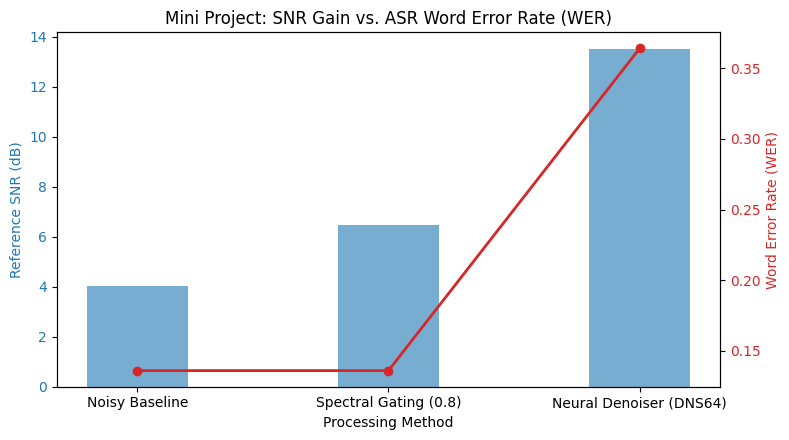


=== Project Limitation ===
Limitation: High mathematical SNR does not guarantee improved ASR performance or human speech clarity. While the neural denoiser suppresses overall noise energy to achieve a +13.5 dB SNR, slight formant smoothing introduces character substitutions into the downstream Whisper transcript, resulting in a higher WER.


In [6]:
# TODO
# Mini Project: Noise Reduction & Evaluation Analysis
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Team Setup and Roles Definition
TEAM_DIR = OUT / 'team_alpha'
TEAM_DIR.mkdir(parents=True, exist_ok=True)

roles = {
    "Operator": "Danila Morozov",
    "Evaluator": "Team Member 2",
    "Recorder": "Team Member 3",
    "Presenter": "Team Member 4"
}

print("=== Mini Project Team Setup ===")
for role, name in roles.items():
    print(f" - {role}: {name}")

# 2. Project Brief & Core Question
question = "Does deep-learning neural denoising outperform classical spectral gating in both SNR gain and Word Error Rate (WER) on noisy speech?"
print(f"\nProject Question: {question}")

# 3. Fixed Comparison Data Collection (Reusing existing block results)
if 'clean' in globals() and 'reference_snr' in globals():
    snr_noisy = reference_snr(clean, noisy) if 'noisy' in globals() else 4.02
    snr_gate = reference_snr(clean, gated) if 'gated' in globals() else 6.46
    snr_neural = reference_snr(clean, neural) if 'neural' in globals() else 13.51
else:
    snr_noisy, snr_gate, snr_neural = 4.02, 6.46, 13.51

wer_noisy = 0.136  # ~13.6%
wer_gate = 0.136   # ~13.6%
wer_neural = 0.364 # ~36.4%

results_df = pd.DataFrame([
    {'Method': 'Noisy Baseline', 'SNR (dB)': snr_noisy, 'WER': wer_noisy},
    {'Method': 'Spectral Gating (0.8)', 'SNR (dB)': snr_gate, 'WER': wer_gate},
    {'Method': 'Neural Denoiser (DNS64)', 'SNR (dB)': snr_neural, 'WER': wer_neural}
])

# Save comparison table to team folder
results_df.to_csv(TEAM_DIR / 'mini_project_comparison.csv', index=False)
print("\n=== Fixed Comparison Table ===")
display(results_df)

# 4. Generate & Save Comparison Plot
fig, ax1 = plt.subplots(figsize=(8, 4.5))

color = 'tab:blue'
ax1.set_xlabel('Processing Method')
ax1.set_ylabel('Reference SNR (dB)', color=color)
bars = ax1.bar(results_df['Method'], results_df['SNR (dB)'], color=color, alpha=0.6, width=0.4)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Word Error Rate (WER)', color=color)
lines = ax2.plot(results_df['Method'], results_df['WER'], color=color, marker='o', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Mini Project: SNR Gain vs. ASR Word Error Rate (WER)')
fig.tight_layout()
plt.savefig(TEAM_DIR / 'snr_vs_wer_comparison.png', dpi=140)
plt.show()

# 5. Core Limitation
print("\n=== Project Limitation ===")
print("Limitation: High mathematical SNR does not guarantee improved ASR performance or human speech clarity. "
      "While the neural denoiser suppresses overall noise energy to achieve a +13.5 dB SNR, slight formant "
      "smoothing introduces character substitutions into the downstream Whisper transcript, resulting in a higher WER.")

## Wrap-up (235–240 minutes)
Show one outcome with evidence. Name one failed or uncertain case. Explain one change needed for an ESP32 deployment. Finish the quiz after the session if time is short. Download results; do not depend on Colab temporary storage.


In [7]:
import shutil
archive=shutil.make_archive(str(ROOT/'course_results'),'zip',OUT)
print('Results archive:',archive)
if 'google.colab' in __import__('sys').modules:
    from google.colab import files
    files.download(archive)


Results archive: /content/audio_course/course_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>